In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(1)

## 1. Data

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
train: (60000, 28, 28)  test: (10000, 28, 28)


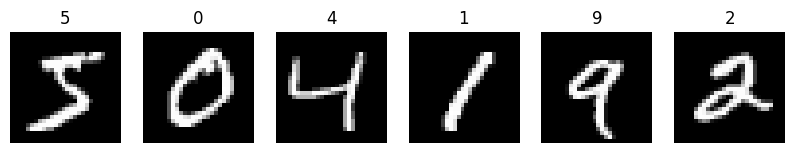

In [2]:
(x_tr, y_tr), (x_te, y_te) = tf.keras.datasets.mnist.load_data()
print("train:", x_tr.shape, " test:", x_te.shape)

# add a channel axis and scale to [0, 1]
x_tr = (x_tr[..., None] / 255.0).astype("float32")
x_te = (x_te[..., None] / 255.0).astype("float32")

fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax, img, lab in zip(axes, x_tr[:6], y_tr[:6]):
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(lab); ax.axis("off")
plt.show()

## 2. Model

In [3]:
cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Training

In [4]:
history = cnn.fit(x_tr, y_tr, epochs=5, batch_size=128, validation_split=0.1)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 108ms/step - accuracy: 0.9251 - loss: 0.2467 - val_accuracy: 0.9827 - val_loss: 0.0611
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 105ms/step - accuracy: 0.9776 - loss: 0.0715 - val_accuracy: 0.9892 - val_loss: 0.0391
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 104ms/step - accuracy: 0.9846 - loss: 0.0506 - val_accuracy: 0.9908 - val_loss: 0.0358
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 107ms/step - accuracy: 0.9875 - loss: 0.0397 - val_accuracy: 0.9912 - val_loss: 0.0324
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 102ms/step - accuracy: 0.9891 - loss: 0.0327 - val_accuracy: 0.9930 - val_loss: 0.0281


## 4. Evaluation

Test accuracy: 0.9905   Test loss: 0.0279


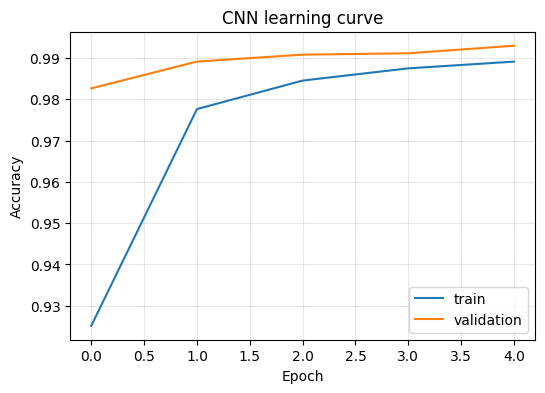

In [5]:
test_loss, test_acc = cnn.evaluate(x_te, y_te, verbose=0)
print(f"Test accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("CNN learning curve"); plt.show()

## 5. Spot-check predictions

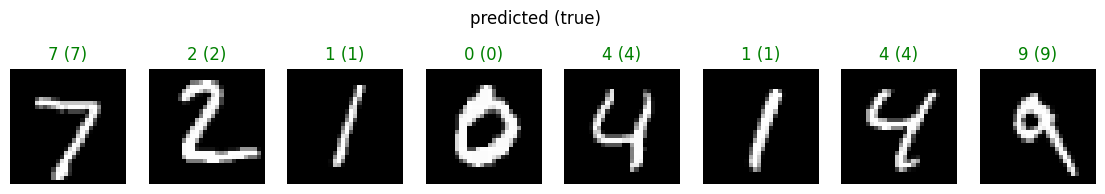

In [6]:
probs = cnn.predict(x_te[:8], verbose=0)
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, img, p, t in zip(axes, x_te[:8], probs.argmax(1), y_te[:8]):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{p} ({t})", color="green" if p == t else "red"); ax.axis("off")
fig.suptitle("predicted (true)"); plt.show()